# Laboratorio A

**Curso**: Diseño de Ecosistemas de Datos para Data Science

**Programa**: Magíster en Data Science

**Universidad del Desarrollo**

**Nombre estudiante**: Luciano Hernández

**Fecha**: 01/11/2026

## Creación del Dataframe

In [1]:
import numpy as np
import pandas as pd

np.random.seed(42)
n_samples = 1000

ids = [f'EST-{str(i).zfill(4)}' for i in range(1, n_samples + 1)]
modes = np.random.choice(['In Person', 'Hibrid'], n_samples, p=[0.65, 0.35])
working = np.random.choice(['Works', "Doesn't Work"], n_samples, p=[0.45, 0.55])

# Attendance depends on working condition
attendance = np.where(
    working == 'Works',
    np.clip(np.random.beta(5, 3, n_samples), 0, 1),
    np.clip(np.random.beta(7, 2, n_samples), 0, 1)
)

academic_load = np.random.randint(1, 7, n_samples)

previous_average = np.clip(np.random.normal(5.2, 0.9, n_samples), 1.0, 7.0)

# Pass probability depends on attendance and previous average
pass_prob = np.clip((attendance * 0.6) + ((previous_average - 1) / 6) * 0.4, 0, 1)
subjects_passed = np.random.binomial(academic_load, pass_prob)

# Dropping out risk logistic calculation
# Higher risk if: Works, low attendance, high fails, low average
fails = academic_load - subjects_passed
logit = -2.0 \
        + 1.2 * (working == 'Works') \
        - 3.5 * attendance \
        + 0.8 * fails \
        - 0.5 * (previous_average - 4.0)

prob = 1 / (1 + np.exp(-logit))
dropping_out_risk = np.random.binomial(1, prob)

df = pd.DataFrame({
    'id': ids,
    'mode': modes,
    'working_condition': working,
    'attendance_percentage': np.round(attendance, 4),
    'academic_load': academic_load,
    'subjects_passed': subjects_passed,
    'previous_average': np.round(previous_average, 2),
    'dropping_out_risk': dropping_out_risk
})

csv_string = df.to_csv(index=False)
#print(csv_string)

In [23]:
rows, cols = df.shape
colNames = list(df.columns)
print("Cantidad de registros:", rows)
print("Cantidad de variables:", cols)
print("Nombres de columnas:\n\t-", "\n\t- ".join(colNames))
print("Primeros registros:")
display(df.head())

Cantidad de registros: 1000
Cantidad de variables: 8
Nombres de columnas:
	- id
	- mode
	- working_condition
	- attendance_percentage
	- academic_load
	- subjects_passed
	- previous_average
	- dropping_out_risk
Primeros registros:


,id,mode,working_condition,attendance_percentage,academic_load,subjects_passed,previous_average,dropping_out_risk
0,EST-0001,In Person,Works,0.6632,2,1,5.75,0
1,EST-0002,Hibrid,Doesn't Work,0.7922,1,0,5.81,0
2,EST-0003,Hibrid,Doesn't Work,0.7864,4,4,5.26,0
3,EST-0004,In Person,Doesn't Work,0.8916,3,2,5.94,0
4,EST-0005,In Person,Doesn't Work,0.8921,6,6,5.37,0


## Análisis Exploratorio de Datos (EDA)

### Gráficos de Barras y de Densidad

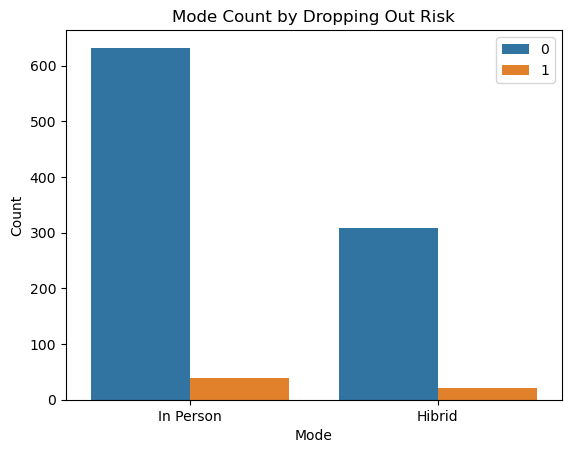

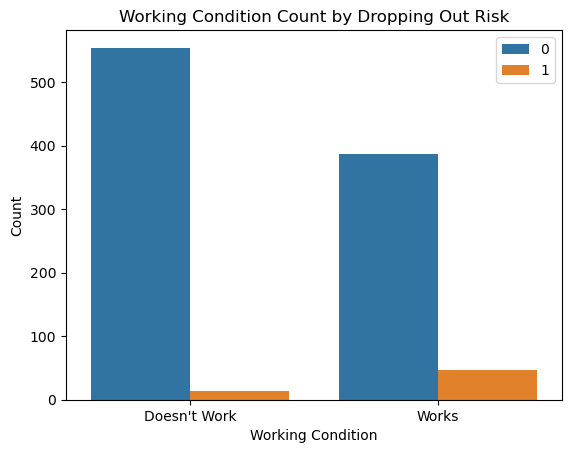

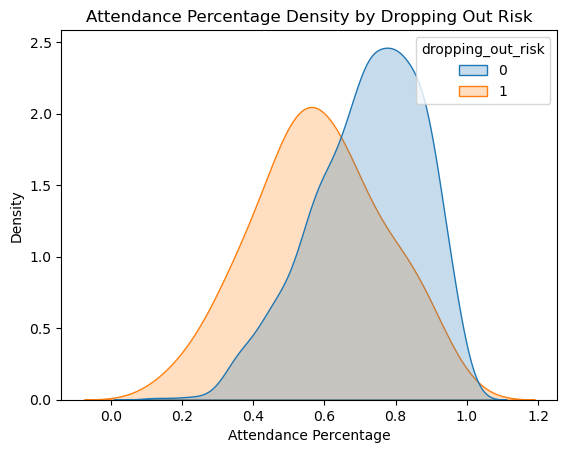

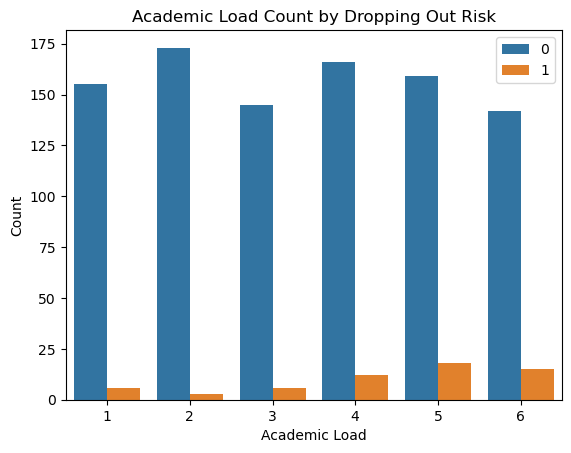

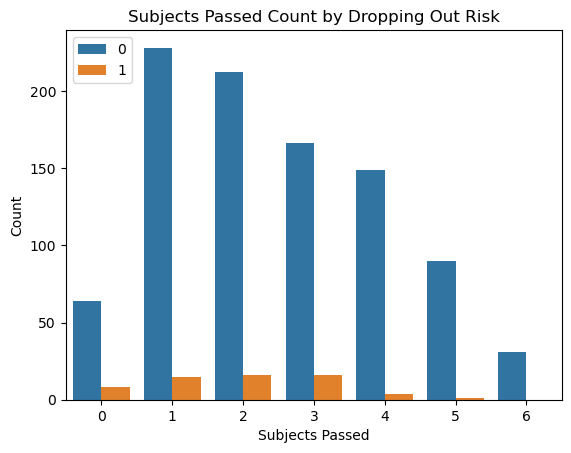

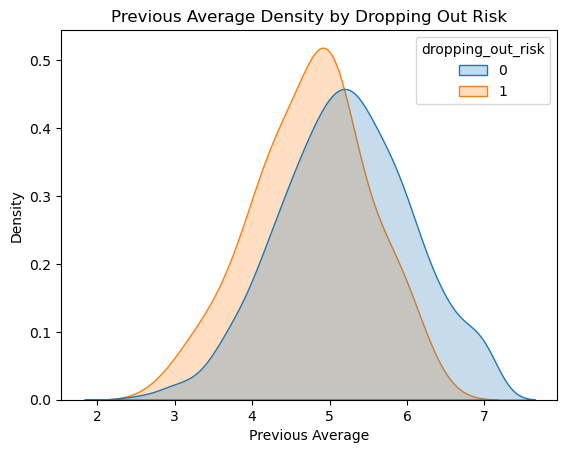

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

denCols = ["attendance_percentage", "previous_average"]

for c in [c0 for c0 in colNames if c0 not in ["id", "dropping_out_risk"]]:
    colTitle = c.replace("_", " ").title()
    if c in denCols:
        sns.kdeplot(data = df, x = c, hue = "dropping_out_risk", common_norm = False, fill = True)
        plt.ylabel("Density")
        plt.title(f"{colTitle} Density by Dropping Out Risk")
    else:
        if pd.api.types.is_numeric_dtype(df[c]):
            order = sorted(df[c].dropna().unique())
        else:
            order = df[c].value_counts().index
        sns.countplot(data = df, x = c, hue = "dropping_out_risk", order = order)
        plt.ylabel("Count")
        plt.title(f"{colTitle} Count by Dropping Out Risk")
        plt.legend()
    plt.xlabel(colTitle)
    plt.show()

### Matriz de Correlación

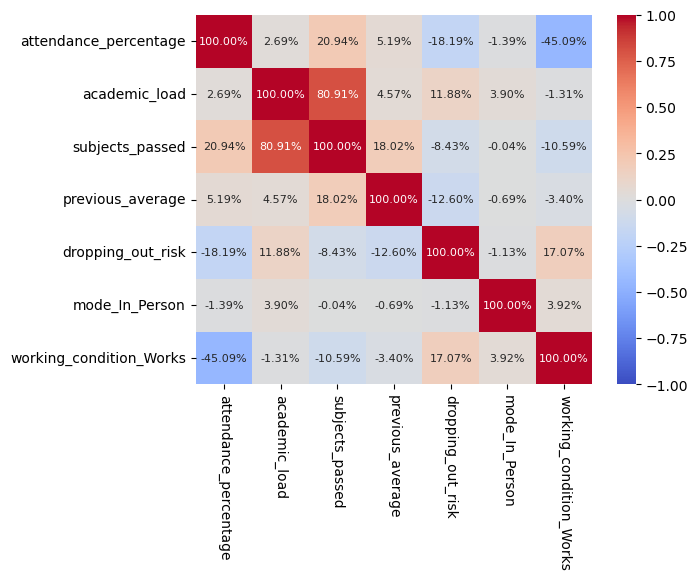

In [4]:
df1 = df.drop(
    columns = ["id"]
).assign(
    mode_In_Person = (df["mode"] == "In Person").astype(int),
    working_condition_Works = (df["working_condition"] == "Works").astype(int)
)

corrMatrix = df1.select_dtypes(include = ["number"]).corr(method = "spearman")
sns.heatmap(
    corrMatrix,
    fmt = "",
    annot = corrMatrix.applymap(lambda x: f"{100 * x:.2f}%"),
    annot_kws = {"size": 8},
    cmap = "coolwarm",
    vmin = -1,
    vmax = 1,
    yticklabels = True,
    xticklabels = True
)
plt.xticks(rotation = -90)
plt.show()

## Entrenamiento del Modelo

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

np.random.seed(42)
df2 = pd.concat([
    df1[df1["dropping_out_risk"] == 0],
    df1[df1["dropping_out_risk"] == 1].sample(
        n = len(df1[df1["dropping_out_risk"] == 0]),
        replace = True,
        random_state = 42
    )
]).sample(
    frac = 1,
    random_state = 42
)
xCols = [
    "mode_In_Person",
    "working_condition_Works",
    "attendance_percentage",
    "academic_load",
    "subjects_passed",
    "previous_average"
]
X = df2[xCols]
Y = df2["dropping_out_risk"]
XTrain, XTest, YTrain, YTest = train_test_split(
    X, Y,
    test_size = 0.2,
    random_state = 1
)
model = LogisticRegression()
model.fit(XTrain, YTrain)
display(pd.DataFrame({
    "Columns": ["Intercept", *xCols],
    "Coefficients": [model.intercept_[0], *model.coef_[0]]
}))

,Columns,Coefficients
0,Intercept,0.884350
1,mode_In_Person,-0.414581
2,working_condition_Works,0.960645
3,attendance_percentage,-1.369975
4,academic_load,0.920479
5,subjects_passed,-1.068447
6,previous_average,-0.282921


## Evaluación del Rendimiento

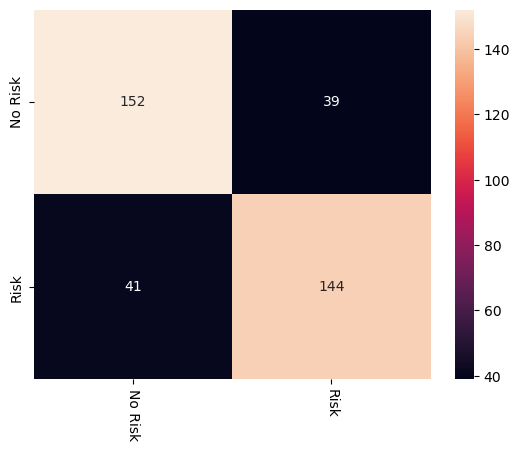

Accuracy: 78.72%
Precision: 78.69%
Recall: 77.84%
ROC AUC: 78.71%


In [6]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, roc_auc_score

YPred = model.predict(XTest)
cm = confusion_matrix(YTest, YPred)
labels = ["No Risk", "Risk"]
sns.heatmap(
    cm,
    fmt = "",
    annot = True,
    xticklabels = labels,
    yticklabels = labels
)
plt.xticks(rotation = -90)
plt.show()
accuracy, precision, recall, roc_auc = (scoreFn(YTest, YPred) for scoreFn in [
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score
])
for scoreName, score in [("Accuracy", accuracy), ("Precision", precision), ("Recall", recall), ("ROC AUC", roc_auc)]:
    print(f"{scoreName}: {score * 100:.2f}%")

## Selección de Umbral

- $\tau$: Umbral
- $C_n$: Costo Asociado a los Falsos Negativos
- $C_p$: Costo Asociado a los Falsos Positivos
- $M$: Cantidad Máxima de Casos que Pueden Revisarse Simultáneamente
- $p$: Probabilidad de que un Estudiante dé su Consentimiento de Recibir Apoyo
- $S$: Número de Estudiantes

### Fórmulas

**Umbral de capacidad nominal**:

$$
\tau = 1 - \frac{M}{S}
$$

Si los puntajes se distribuyen entre 0 y 1, esta fórmula establece un punto de corte que garantiza que las alertas no superen la capacidad humana y operativa disponible en la institución para revisar los casos ($M$) frente al total de estudiantes ($S$).

**Umbral de capacidad ajustado por embudo de aceptación**

$$
\tau = 1 - \frac{M}{p \times S}
$$

Dado que cualquier intervención depende de que el estudiante dé su consentimiento de recibir apoyo, el sistema puede permitirse alertar a un volumen mayor de alumnos asumiendo que solo una proporción $p$ consumirá efectivamente la capacidad $M$.

**Umbral clásico de equilibrio de costos**:

$$
\tau = \frac{C_p}{C_p + C_n}
$$

Pondera exclusivamente el costo que asume la institución al no ofrecer apoyo a tiempo ($C_n$) frente al riesgo de generar alertas que resulten estigmatizantes o innecesarias ($C_p$).

**Umbral de costos ajustado por probabilidad de éxito**:

$$
\tau = \frac{C_p}{C_p + p \times C_n}
$$

Refina la ecuación anterior integrando el comportamiento del estudiante. El beneficio de evitar un falso negativo ($C_n$) solo tiene un impacto real si el alumno otorga su consentimiento ($p$) para ser ayudado.

**Umbral compuesto de escasez operativa y riesgo**:

$$
\tau = \frac{C_p}{p \times C_n} \times \left( 1 - \frac{M}{S} \right)
$$

Combina en una sola expresión la dimensión económica de los errores y la restricción física de recursos. Si la proporción de estudiantes por cupo de atención es muy alta, el umbral debe ser forzosamente más restrictivo para priorizar solo los casos más críticos que pasarán a revisión por parte de una persona.

In [7]:
def clamp(x, minV = 0, maxV = 1):
    return min(maxV, max(minV, x))

def getThresholds(fnCost, fpCost, maxCapacity, constentProb, studentsNumber):
    return [clamp(t) for t in [
        1 - maxCapacity / studentsNumber,
        1 - maxCapacity / (constentProb * studentsNumber),
        fpCost / (fnCost + fpCost),
        fpCost / (fnCost + constentProb * fpCost),
        fpCost / (constentProb * fnCost) * (1 - maxCapacity / studentsNumber)
    ]]

fnCost, fpCost, maxCapacity, constentProb, studentsNumber = (float(input(f"{param}: ")) for param in [
    "Costo Asociado a los Falsos Negativos",
    "Costo Asociado a los Falsos Positivos",
    "Cantidad Máxima de Casos que Pueden Revisarse Simultáneamente",
    "Probabilidad de que un Estudiante dé su Consentimiento de Recibir Apoyo",
    "Número de Estudiantes"
])

thresholds = getThresholds(fnCost, fpCost, maxCapacity, constentProb, studentsNumber)

print("Opciones de Umbral:", ", ".join([f"{t * 100:.2f}%" for t in thresholds]))

Costo Asociado a los Falsos Negativos: 50
Costo Asociado a los Falsos Positivos: 20
Cantidad Máxima de Casos que Pueden Revisarse Simultáneamente: 100
Probabilidad de que un Estudiante dé su Consentimiento de Recibir Apoyo: 0.7
Número de Estudiantes: 1000
Opciones de Umbral: 90.00%, 85.71%, 28.57%, 31.25%, 51.43%


## Nueva Cohorte

In [8]:
import numpy as np
import pandas as pd

np.random.seed(2026)
N = 1000

# 1. id
ids = [f"EST-{str(i).zfill(4)}" for i in range(1, N+1)]

# 2. mode & working_condition
modes = np.random.choice(["Hibrid", "In Person"], p=[0.65, 0.35], size=N)
work_conds = np.random.choice(["Works", "Doesn't Work"], p=[0.75, 0.25], size=N)

# Initialize arrays
academic_load = np.zeros(N, dtype=int)
attendance_percentage = np.zeros(N, dtype=float)
previous_average = np.zeros(N, dtype=float)
subjects_passed = np.zeros(N, dtype=int)
dropping_out_risk = np.zeros(N, dtype=int)

for i in range(N):
    is_working = work_conds[i] == "Works"
    is_hibrid = modes[i] == "Hibrid"
    
    # academic_load: workers take fewer classes
    if is_working:
        academic_load[i] = np.random.choice([1, 2, 3, 4, 5, 6], p=[0.1, 0.2, 0.35, 0.25, 0.08, 0.02])
    else:
        academic_load[i] = np.random.choice([1, 2, 3, 4, 5, 6], p=[0.02, 0.03, 0.1, 0.2, 0.4, 0.25])
        
    # attendance_percentage
    if is_working:
        # workers have lower attendance, hybrid helps a bit
        base_mean = 0.70 if is_hibrid else 0.60
    else:
        base_mean = 0.85 if is_hibrid else 0.90
    
    # sample attendance from beta distribution
    a = base_mean * 10
    b = (1 - base_mean) * 10
    att = np.random.beta(a, b)
    attendance_percentage[i] = np.clip(att, 0.0, 1.0)
    
    # previous_average: correlated slightly with attendance + noise
    base_avg = 4.0 + (attendance_percentage[i] * 2.0) + np.random.normal(0, 0.5)
    previous_average[i] = np.clip(base_avg, 1.0, 7.0)
    
    # subjects_passed: binomial based on attendance and previous avg
    pass_prob = 0.3 + (0.4 * attendance_percentage[i]) + (0.3 * (previous_average[i] - 1)/6)
    pass_prob = np.clip(pass_prob, 0.05, 0.95)
    subjects_passed[i] = np.random.binomial(academic_load[i], pass_prob)
    
    # dropping_out_risk
    # Higher risk if attendance is low, fail rate is high, and working
    fail_rate = (academic_load[i] - subjects_passed[i]) / academic_load[i]
    
    # Logit components
    logit = -3.0 # base risk
    logit += 2.5 * fail_rate
    logit += 2.0 * (1.0 - attendance_percentage[i])
    logit += 0.8 * (1 if is_working else 0)
    logit -= 0.5 * ((previous_average[i] - 4.0) / 3.0)
    
    prob_risk = 1.0 / (1.0 + np.exp(-logit))
    dropping_out_risk[i] = np.random.binomial(1, prob_risk)

# Build DataFrame
dfNew = pd.DataFrame({
    'id': ids,
    'mode': modes,
    'working_condition': work_conds,
    'attendance_percentage': np.round(attendance_percentage, 4),
    'academic_load': academic_load,
    'subjects_passed': subjects_passed,
    'previous_average': np.round(previous_average, 2),
    'dropping_out_risk': dropping_out_risk
})

# Generate CSV string
#csv_str = df.to_csv(index=False)
#with open("data.csv", "w") as f:
#    f.write(csv_str)
#print(f"Stats:\nWork: {(df['working_condition'] == 'Works').mean()}\nMode: {(df['mode'] == 'Hibrid').mean()}")

#with open("data.csv", "r") as f:
#    print(f.read())

In [9]:
rowsNew, colsNew = dfNew.shape
colNamesNew = list(dfNew.columns)
print("Cantidad de registros:", rowsNew)
print("Cantidad de variables:", colsNew)
print("Nombres de columnas:\n\t-", "\n\t- ".join(colNamesNew))
print("Primeros registros:")
display(dfNew.head())

Cantidad de registros: 1000
Cantidad de variables: 8
Nombres de columnas:
	- id
	- mode
	- working_condition
	- attendance_percentage
	- academic_load
	- subjects_passed
	- previous_average
	- dropping_out_risk
Primeros registros:


,id,mode,working_condition,attendance_percentage,academic_load,subjects_passed,previous_average,dropping_out_risk
0,EST-0001,Hibrid,Works,0.7706,3,3,5.51,0
1,EST-0002,Hibrid,Works,0.7964,4,4,5.34,0
2,EST-0003,In Person,Works,0.3909,5,3,5.73,0
3,EST-0004,Hibrid,Doesn't Work,0.9087,4,3,5.98,0
4,EST-0005,Hibrid,Doesn't Work,0.8510,5,4,5.68,0


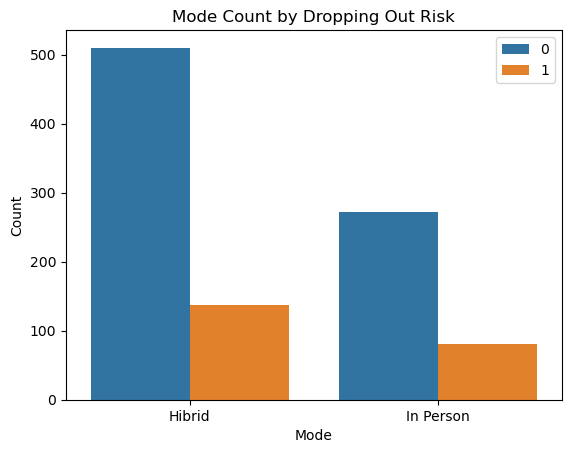

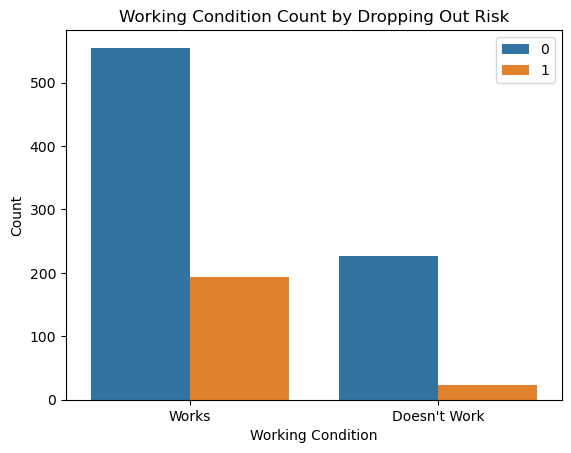

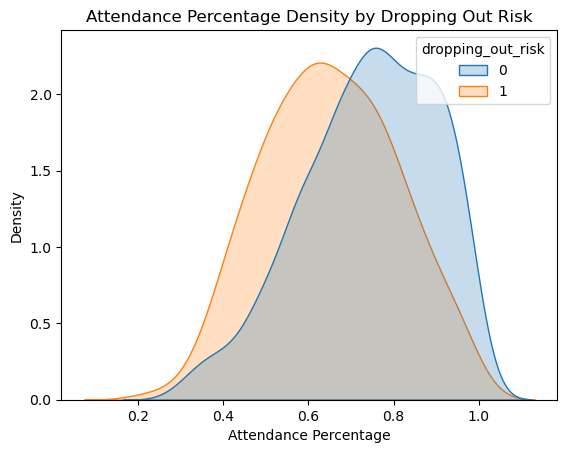

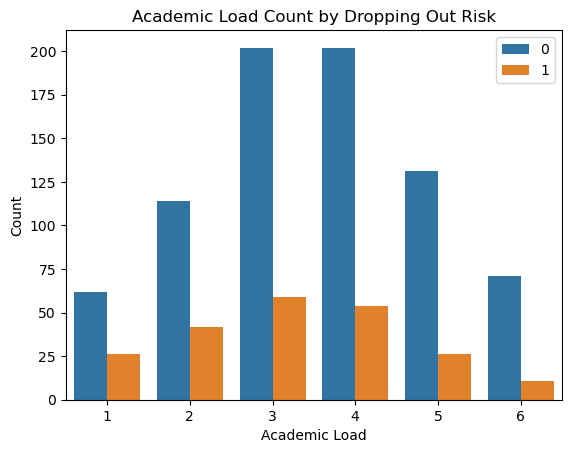

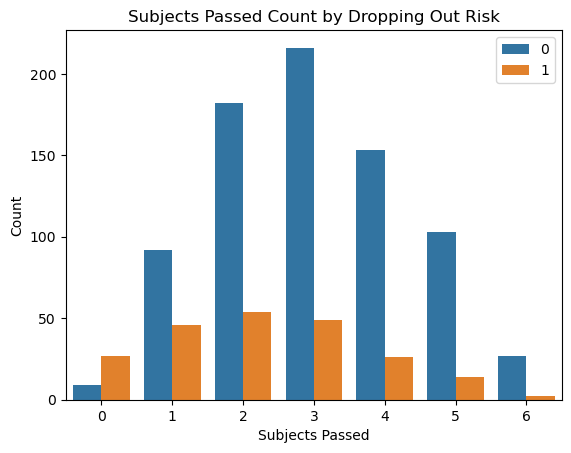

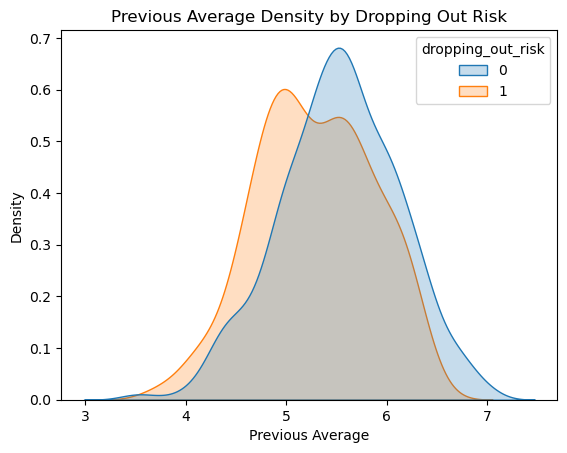

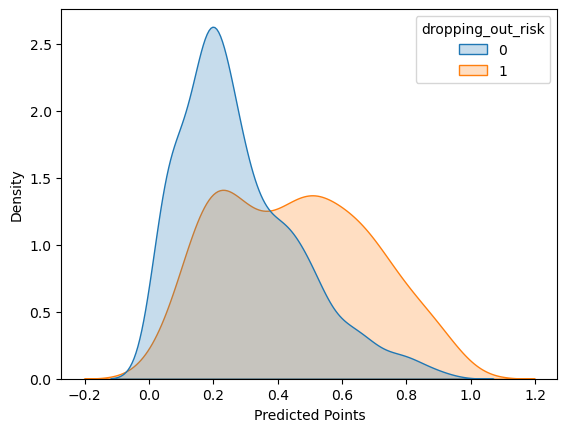

In [16]:
for c in [c0 for c0 in colNames if c0 not in ["id", "dropping_out_risk"]]:
    colTitle = c.replace("_", " ").title()
    if c in denCols:
        sns.kdeplot(data = dfNew, x = c, hue = "dropping_out_risk", common_norm = False, fill = True)
        plt.ylabel("Density")
        plt.title(f"{colTitle} Density by Dropping Out Risk")
    else:
        if pd.api.types.is_numeric_dtype(dfNew[c]):
            order = sorted(dfNew[c].dropna().unique())
        else:
            order = dfNew[c].value_counts().index
        sns.countplot(data = dfNew, x = c, hue = "dropping_out_risk", order = order)
        plt.ylabel("Count")
        plt.title(f"{colTitle} Count by Dropping Out Risk")
        plt.legend()
    plt.xlabel(colTitle)
    plt.show()
np.random.seed(42)
dfNew1 = dfNew.drop(
    columns = ["id"]
).assign(
    mode_In_Person = (dfNew["mode"] == "In Person").astype(int),
    working_condition_Works = (dfNew["working_condition"] == "Works").astype(int)
)
XTestNew = dfNew1[xCols]
YTestNew = dfNew1["dropping_out_risk"]
probabilities = model.predict_proba(XTestNew)[:, 1]
sns.kdeplot(data = dfNew.assign(probabilities = probabilities), x = "probabilities", hue = "dropping_out_risk", common_norm = False, fill = True)
plt.ylabel("Density")
plt.xlabel("Predicted Points")
plt.show()

With Threshold = 90.00%


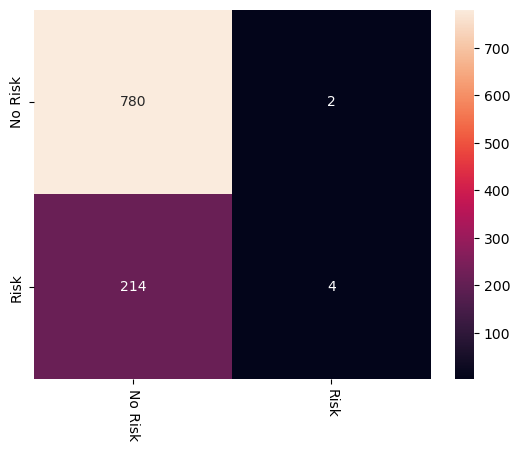

With Threshold = 85.71%


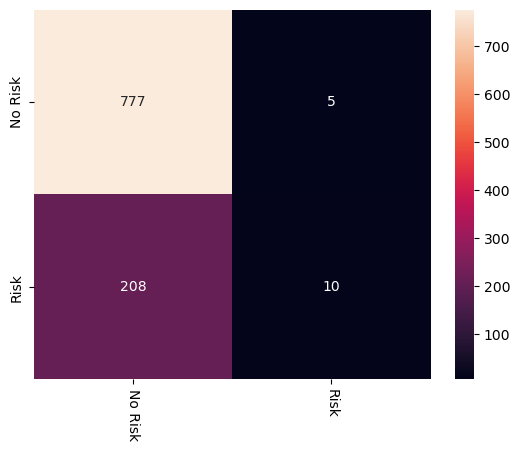

With Threshold = 28.57%


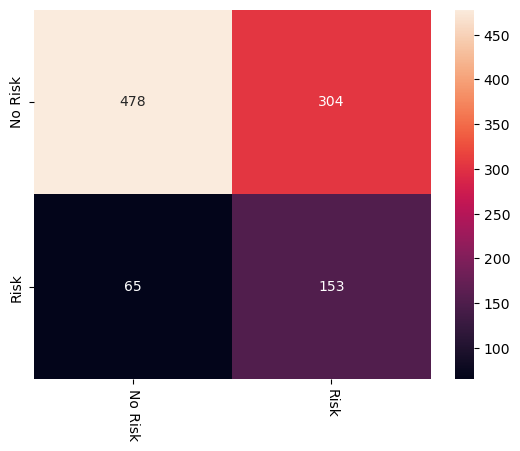

With Threshold = 31.25%


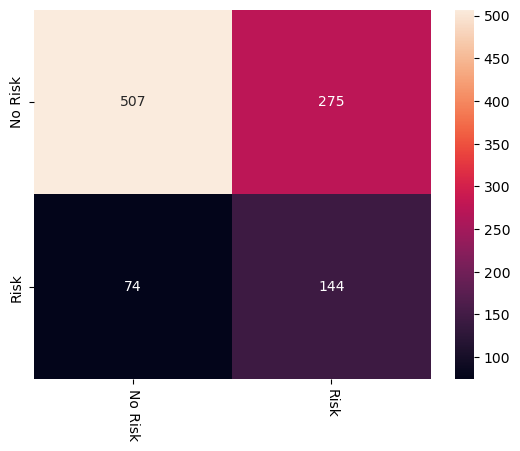

With Threshold = 51.43%


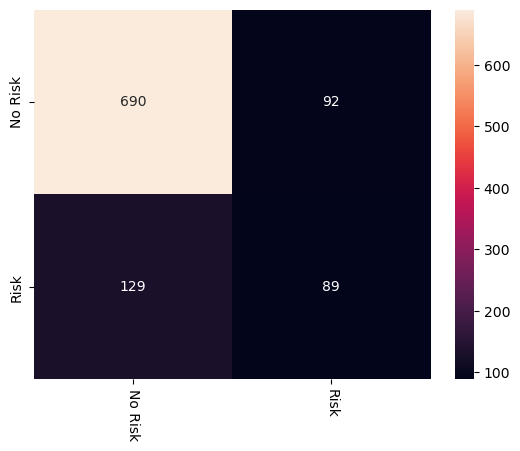

,Accuracy,Precision,Recall,ROC AUC
Threshold,,,,
0.900000,0.784,0.666667,0.018349,0.507896
0.857143,0.787,0.666667,0.045872,0.519739
0.285714,0.631,0.334792,0.701835,0.656544
0.312500,0.651,0.343675,0.660550,0.654444
0.514286,0.779,0.491713,0.408257,0.645305


The max Accuracy is 79.50% when Threshold is 60.60%


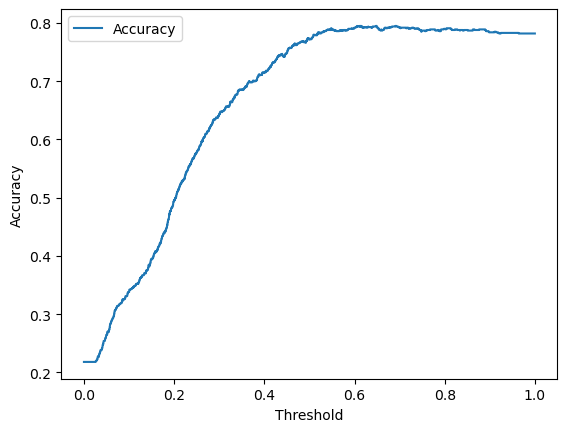

The max Precision is 100.00% when Threshold is 92.43%


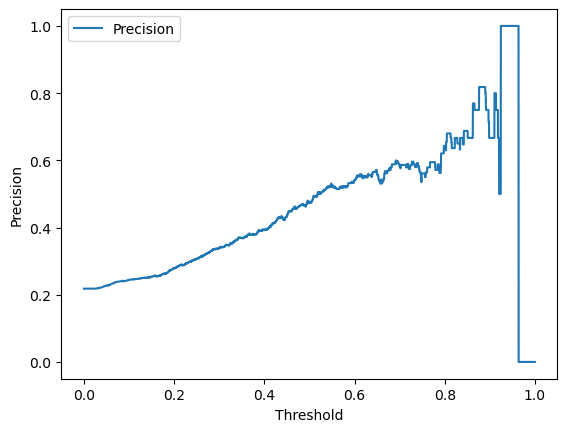

The max Recall is 100.00% when Threshold is 0.01%


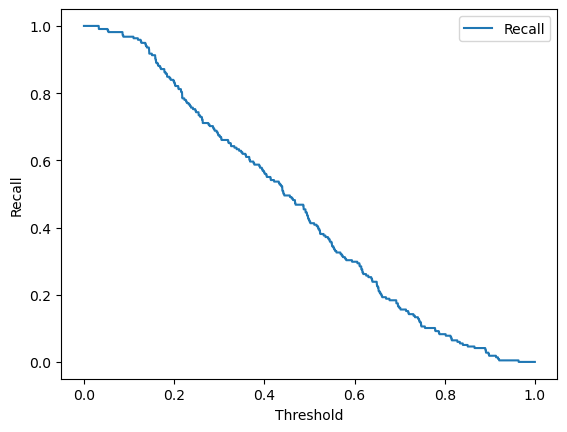

The max ROC AUC is 66.99% when Threshold is 43.21%


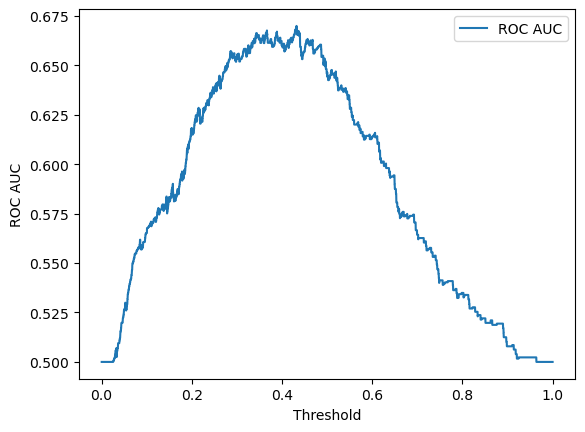

The max Scores Product is 11.56% when Threshold is 43.21%
	- Accuracy: 74.50%
	- Precision: 43.17%
	- Recall: 53.67%
	- ROC AUC: 66.99%


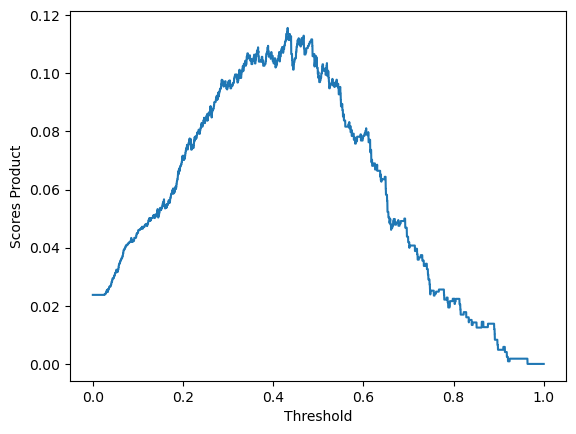

In [21]:
YPredNews = [ (probabilities >= t).astype(int) for t in thresholds ]
cmNews = [ confusion_matrix(YTestNew, ypn) for ypn in YPredNews ]
for i in range(len(thresholds)):
    print(f"With Threshold = {thresholds[i] * 100:.2f}%")
    sns.heatmap(
        cmNews[i],
        fmt = "",
        annot = True,
        xticklabels = labels,
        yticklabels = labels
    )
    plt.xticks(rotation = -90)
    plt.show()
accuracyNews, precisionNews, recallNews, roc_aucNews = ([ scoreFn(YTestNew, ypn) for ypn in YPredNews ] for scoreFn in [
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score
])

display(pd.DataFrame({
    "Threshold": thresholds,
    "Accuracy": accuracyNews,
    "Precision": precisionNews,
    "Recall": recallNews,
    "ROC AUC": roc_aucNews
}).set_index("Threshold"))

tMany = [ i / 10000 for i in range(1, 10000) ]
scoresDf = pd.DataFrame({
    "Threshold": tMany,
    **{ scoreName: [ scoreFn(YTestNew, (probabilities >= t).astype(int)) for t in tMany ] for scoreName, scoreFn in [("Accuracy", accuracy_score), ("Precision", lambda yt, yp: precision_score(yt, yp, zero_division = 0)), ("Recall", recall_score), ("ROC AUC", roc_auc_score)] }
}).set_index("Threshold")
scoresProducts = 1
for c in scoresDf.columns:
    scoresProducts *= scoresDf[c]
    print(f"The max {c} is {scoresDf[c].max() * 100:.2f}% when Threshold is {scoresDf[c].idxmax() * 100:.2f}%")
    scoresDf.plot(y = c, use_index = True)
    plt.ylabel(c)
    plt.xlabel(scoresDf.index.name)
    plt.show()
print(f"The max Scores Product is {scoresProducts.max() * 100:.2f}% when Threshold is {scoresProducts.idxmax() * 100:.2f}%")
for c in scoresDf.columns:
    print(f"\t- {c}: {scoresDf[c][scoresProducts.idxmax()] * 100:.2f}%")
scoresProducts.plot(use_index = True)
plt.ylabel("Scores Product")
plt.xlabel(scoresDf.index.name)
plt.show()

## Evaluar Mitigaciones

### Revisar calidad y cambios en la definición de las variables

Requiere alertas de *data drift* o cambios estructurales en los datos de entrada. Esto se evidencia si las distribuciones de variables clave cambian drásticamente respecto al marco de datos original, como alteraciones en la asistencia (`attendance_percentage`), variaciones en la proporción de estudiantes que trabajan (`working_condition`), o en las modalidades de estudio (`mode`). También es necesario si se detectan valores nulos masivos causados por fallos en los pipelines de datos.

### Aumentar temporalmente la revisión humana

Se justifica si las predicciones del modelo comienzan a concentrarse en zonas de alta incertidumbre, o si se registran quejas o anomalías en las intervenciones operativas basadas en el modelo. Actúa como barrera temporal ante un deterioro rápido del Recall (actualmente 53.67%) o Precisión (43.01%) mientras se diagnostica la causa.

### Ajustar el umbral según capacidad y costo de error

Exige una validación matemática de las curvas de desempeño contrastada con los objetivos de negocio y la capacidad operativa. Si el costo de intervenir a un estudiante (falso positivo) es muy alto, el umbral debe ajustarse hacia el 92.5% para garantizar una Precisión del 100%. Si dejar escapar a un alumno en riesgo (`dropping_out_risk`) es inaceptable, el umbral debe bajarse (apuntando al 100% de Recall en umbrales bajos) o situarse en el 43.2% para maximizar el producto de los scores en caso de buscar equilibrio.

### Recalibrar las probabilidades

Se requiere confirmar que la capacidad discriminativa del modelo se mantiene estable (ej. ROC AUC sostenido en 66.92%), pero que los valores numéricos devueltos ya no representan fielmente la verdadera tasa empírica de ocurrencia de la clase positiva.

### Recolectar nuevas etiquetas

Es necesario cuando se confirma un *concept drift*. Esto ocurre si existe evidencia del negocio de que las reglas subyacentes cambiaron (por ejemplo, nuevas normativas de aprobación de asignaturas, `subjects_passed`) y la relación lógica entre las características predictoras y la variable objetivo se ha transformado permanentemente.

### Reentrenar con datos recientes

Exige comprobar una caída sostenida en las métricas de clasificación (Accuracy degradándose por debajo del 74.40%) a lo largo del tiempo, y requiere tener evidencia previa, usualmente mediante un entorno de experimentación, de que incorporar lotes nuevos de datos efectivamente restaura la métrica sin generar sobreajuste.

### Suspender el uso cuando exista riesgo relevante o una condición crítica incumplida

Esta medida extrema requiere evidencia de un daño directo y grave. Se aplica si ocurre una falla técnica completa en el pipeline, si el modelo exhibe sesgos perjudiciales descubiertos post-despliegue que afectan a grupos específicos, o si las métricas caen a un nivel donde el modelo rinde peor que una asignación aleatoria, violando regulaciones de compliance operativo.